# Reinforcement Learning: Q-learning for the Contact Strategy

## The business problem

- The agency can contact a debtor by **phone, email or letter**. Each channel costs money, and works differently for different debtors
- So far we **predicted** outcomes: will a debtor repay, and how much. Now the question is a **decision**: which channel should we use for which debtor, so that the money recovered minus the contact cost is as large as possible?
- A prediction does not tell us what to do. **Reinforcement learning** learns a decision rule, called a **policy**, by trial and error

## Why not a supervised model?

- There is no label "the best channel" in the data. We only see the channel that was actually used, and what followed
- A contact also changes what happens next, because the debtor's situation changes. Supervised learning treats every row as independent

## A simplified problem

We solve a small version of the problem, with a table of values that we can read and check, and no neural network:

| Component | Simplified definition |
|---|---|
| State | 3 risk categories: low, medium, high, derived from the repayment probability |
| Action | 3 contact options: phone call, email, letter |
| Reward | Repayment received minus contact cost |
| Update rule | The Bellman equation, with Q(s, a) updated iteratively through ε-greedy exploration |

## What this notebook does

- Defines the components of the problem: states, actions, rewards and transitions
- Implements the Q-learning update, with ε-greedy exploration
- Plots the Q-values over the episodes, and compares a constant learning rate with a decaying one
- Extracts the policy from the Q-table and interprets it
- Uses only `numpy` and `random` for the learning itself

## 1. The Data

We need the data for two things only:

- **The states:** each account gets a risk category (low, medium or high), derived from its predicted probability of repayment
- **The amount received** when a debtor repays, for the reward

We use the **train** accounts only, as in the earlier notebooks. The environment of the agent is built from the training period.

### 1.1 Imports and loading the data

In [1]:
import numpy as np                                      # arrays, and the Q-table
import pandas as pd                                     # loading and filtering the data
import random                                           # random choices, for ε-greedy exploration and for the outcomes
import matplotlib.pyplot as plt                         # plots
import sklearn                                          # imported only to print its version
from sklearn.linear_model import LogisticRegression     # estimates the probability of repayment, as in the Linear/Logistic Regression notebook


In [2]:
# Record the versions, so results can be tied to a setup
print('pandas:', pd.__version__, '| numpy:', np.__version__, '| scikit-learn:', sklearn.__version__)

# Load the feature matrix produced by the EDA notebook. One row per account
DATA_DIR = "data/"
master = pd.read_pickle(DATA_DIR + 'cleaned_dataset.pkl')

# The three numeric features we use to estimate the probability of repayment.
# No encoding is needed for these, which keeps this notebook short
features = ['log_days_past_due', 'missed_payments', 'broken_arrangements']

df_train = master[master['split'] == 'train']      # the train accounts only
rows_before = len(df_train)                        # number of train accounts before dropping
df_train = df_train.dropna(subset=features)        # the model cannot handle missing values
print(f'Train accounts: {len(df_train):,} (dropped {rows_before - len(df_train)} with a missing feature)')
print()
print('Share of accounts that repay within 90 days:', round(df_train['repayment_probability'].mean(), 3))
df_train[features].describe().round(2)  # a first look at the three features

pandas: 3.0.3 | numpy: 2.4.6 | scikit-learn: 1.9.1
Train accounts: 8,894 (dropped 74 with a missing feature)

Share of accounts that repay within 90 days: 0.254


,log_days_past_due,missed_payments,broken_arrangements
count,8894.00,8894.00,8894.00
mean,5.63,11.22,1.31
std,0.73,7.29,1.46
min,3.43,1.00,0.00
25%,5.11,5.00,0.00
50%,5.79,10.00,1.00
75%,6.19,16.00,2.00
max,6.90,35.00,6.00


**QUESTIONS:**

- We use only three numeric features, and only the train accounts. What do we lose with three features? What would go wrong if the states were built from all the rows, including test?
- `repayment_probability` in the data is a 0 or 1 label, not a probability. What does that mean for how we get a probability for each account?

### 1.2 Risk states from the predicted probability of repayment

We need each account to have one of three **states**, so the agent can learn a separate best action for each. We build them in three steps:

1. **Predict a probability.** The data holds only the observed outcome (1 if the account repaid within 90 days, 0 if not). We fit a **logistic regression** to predict that outcome, as in the Linear/Logistic Regression notebook. Its output is a number between 0 and 1 for every account, the **predicted probability of repayment** $\hat{p}$
2. **Cut into three equal groups.** We sort the accounts by $\hat{p}$ and cut the list at its **terciles**, the two values that split the accounts into thirds. The two values are the **cut points**:
   - **High risk:** the lowest third of $\hat{p}$ (unlikely to repay)
   - **Medium risk:** the middle third
   - **Low risk:** the highest third (likely to repay)
3. **Label every account** by comparing its $\hat{p}$ with the cut points

**Choices we made, and why**

- **Three features only:** `log_days_past_due`, `missed_payments` and `broken_arrangements`. These were the three most important variables in the random forest for this target, they are numeric, so no encoding is needed, and they all describe how delinquent an account is. The cost is that the states say nothing about the debt type or the debtor. A model with all features would give better probabilities, but would need much more code, and the notebook is about learning a policy, not about the best model
- **Terciles instead of fixed cut points:** only about a quarter of the accounts repay, so very few would reach a threshold like 0.6, and a state would be nearly empty. Terciles guarantee that every state has about a third of the accounts
- **No `class_weight`:** class weights shift the predicted probabilities upwards. Here we want probabilities that mean what they say
- **Train only:** the model and the cut points are computed on the train accounts

In [10]:
##########################################################
## Fit the model, cut the probabilities into 3 states    ##
##########################################################
X_fit_states = df_train[features]                 # the three numeric features
y_fit_states = df_train['repayment_probability']  # 1 if the account repays within 90 days, 0 otherwise

# No class_weight, so the predicted probabilities are not shifted
state_model = LogisticRegression()
state_model.fit(X_fit_states, y_fit_states)

# Predicted probability of repayment for every train account (column 1 is the probability of class 1)
p_hat = state_model.predict_proba(X_fit_states)[:, 1]

# The two cut points: the 33rd and 67th percentile of the predicted probabilities
cut_low, cut_high = np.quantile(p_hat, [1/3, 2/3])
print(f'Cut points: {cut_low:.3f} and {cut_high:.3f}')

states = ['Low risk', 'Medium risk', 'High risk']     # the names of the three states, in this order

def risk_state(p):
    """Maps a predicted probability of repayment to a risk state.

    Args:
        p (float): Predicted probability that the account repays.

    Returns:
        str: 'High risk' (lowest third), 'Medium risk' or 'Low risk' (highest third).
    """
    if p < cut_low:
        return 'High risk'
    elif p < cut_high:
        return 'Medium risk'
    else:
        return 'Low risk'

df_train = df_train.copy()                                      # avoid a warning about changing a slice
df_train['state'] = [risk_state(p) for p in p_hat]              # the state of every account

# A check: the three states should have about a third of the accounts each,
# and the share of repayers should rise from high to low risk
summary = df_train.groupby('state')['repayment_probability'].agg(['count', 'mean']).loc[states]
summary.columns = ['accounts', 'share that repays']
summary.round(3)

Cut points: 0.116 and 0.280


,accounts,share that repays
state,,
Low risk,2965,0.505
Medium risk,2964,0.149
High risk,2965,0.108


**QUESTIONS:**

- Look at the table. Do the three states hold about a third of the accounts each? Does the share of repayers rise from high to low risk? Why does that have to be the case?
- Why did we leave out `class_weight='balanced'` here, when we used it in the earlier notebooks?
- The cut points depend on the data they are computed from. What would happen to the states if you computed them on the test accounts instead?
- We fitted the model and cut the probabilities on the same accounts. Does that create a problem for the states? How would you avoid it?

## 2. The MDP Components

We define the components of the problem, as in the reference:

- **States:** the three risk states from 1.2
- **Actions:** phone, email or letter
- **Contact cost:** every contact costs money, whether or not the debtor repays
- **Amount received:** if the debtor repays, we receive an amount. We take the mean `repayment_amount` of the repayers in each state, from the train accounts
- **Reward:** the amount received, if the debtor repays, minus the contact cost
- **Q-table:** a table with one row per state and one column per action, that holds our estimate of how good each action is in each state. It starts at zero

In [11]:
##########################################################
## The MDP components: actions, costs, rewards, Q-table  ##
##########################################################
actions = ['Phone', 'Email', 'Letter']   # the three contact options

# Typical cost of one contact, in EUR
contact_cost = {'Phone': 4.20, 'Email': 0.15, 'Letter': 2.50}

# Amount received when a debtor repays: the mean repayment_amount of the repayers in each state
repayers = df_train[df_train['repayment_probability'] == 1]            # the accounts that repaid
amount_received = repayers.groupby('state')['repayment_amount'].mean() # mean amount per state
amount_received = amount_received.loc[states]                          # in the order of the states list

def reward(state, action, repaid):
    """Computes the reward of one contact.

    Args:
        state (str): The risk state of the account, one of the three states.
        action (str): The contact option used: 'Phone', 'Email' or 'Letter'.
        repaid (bool): True if the debtor repays after this contact.

    Returns:
        float: The amount received (if the debtor repays) minus the contact cost.
    """
    received = amount_received[state] if repaid else 0.0   # money received after this contact
    return received - contact_cost[action]                 # the contact cost is paid either way

# The Q-table: one row per state, one column per action, all zeros at the start
q_table = np.zeros((len(states), len(actions)))

print('States: ', states)
print('Actions:', actions)
print()
print('Contact cost (EUR):')
print(contact_cost)
print()
print('Mean amount received when a debtor repays (EUR):')
print(amount_received.round(2))
print()
print('Initial Q-table:')
print(q_table)

States:  ['Low risk', 'Medium risk', 'High risk']
Actions: ['Phone', 'Email', 'Letter']

Contact cost (EUR):
{'Phone': 4.2, 'Email': 0.15, 'Letter': 2.5}

Mean amount received when a debtor repays (EUR):
state
Low risk        85.63
Medium risk     90.37
High risk      108.36
Name: repayment_amount, dtype: float64

Initial Q-table:
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


**QUESTIONS:**

- What do the rows and the columns of the Q-table stand for? What will a value in it mean once the agent has learned?
- Look at the mean amount received in each state. Does it differ between the states? Why might it?
- Compare the contact costs with the amount received. Before any learning, which channel would you expect to be best in each state? What else would you need to know?
- The contact cost is paid whether or not the debtor repays. Why is that the right way to model a contact?

## 3. The Environment: Payment Probabilities and Transitions

The agent learns from experience, so we need an **environment** that answers each contact. When the agent contacts an account in state $s$ with action $a$, the environment returns three things:

- whether the debtor **pays**
- a **reward**
- the **next state** of the account

The payment probabilities and the transition rule are **assumptions** that we state openly.

### 3.1 The payment probability

The chance that a debtor in state $s$ pays after a contact on channel $a$ is $p(s, a)$. The table has $3 \times 3 = 9$ values.

- **"Pays"** means that the debtor makes at least one payment, as in the EDA notebook. It does **not** mean that the whole balance is paid
- Each value answers a separate "what if" question: *if* we use this channel in this state, how likely is a payment? Only one channel is used in a real contact, so the values in a row are not alternatives of one event, and they do not need to add up to 1

### 3.2 The transition rule

Two different things happen in a contact, and they should not be mixed up:

1. **The outcome.** The debtor pays or does not pay. This is random, with the probability $p(s, a)$ from 3.1
2. **The move.** The account goes to a next state $s'$. The outcome decides where, through a **rule that we choose**:

| Current state | Outcome | Next state |
|---|---|---|
| Low risk | pays | Low risk |
| Low risk | does not pay | Medium risk |
| Medium risk | pays | Low risk |
| Medium risk | does not pay | High risk |
| High risk | pays | Low risk |
| High risk | does not pay | High risk |

Because the outcome is random, the next state is random too. The **transition probability** $P(s' \mid s, a)$ is the probability that the account ends up in $s'$. We find it by adding the probabilities of the outcomes that lead to $s'$:

$$P(s' \mid s, a) = \sum_{\text{outcomes that lead to } s'} P(\text{outcome} \mid s, a)$$

**Example:** a Medium-risk account is contacted by phone, with $p(\text{Medium}, \text{Phone}) = 0.19$.

- The debtor pays (probability 0.19), and the rule sends the account to Low. So $P(\text{Low} \mid \text{Medium}, \text{Phone}) = 0.19$
- The debtor does not pay (probability 0.81), and the rule sends the account to High. So $P(\text{High} \mid \text{Medium}, \text{Phone}) = 0.81$
- No outcome leads to Medium. So $P(\text{Medium} \mid \text{Medium}, \text{Phone}) = 0$

**Moving to Low risk is not the same as paying.** Paying is the outcome, and moving is the result of our rule. Here the two probabilities coincide, because paying is the only way to reach Low. With a different rule, for example one where a payer stays in the same state, $p(s, a)$ would not change, but the transition probabilities would.

For one channel $a$, all the transition probabilities fit in one matrix. Rows are the current state $s$, columns are the next state $s'$, and every row adds up to 1:

$$
T_a =
\begin{array}{c|ccc}
 & \text{Low} & \text{Medium} & \text{High} \\ \hline
\text{Low} & p(\text{Low}, a) & 1 - p(\text{Low}, a) & 0 \\
\text{Medium} & p(\text{Medium}, a) & 0 & 1 - p(\text{Medium}, a) \\
\text{High} & p(\text{High}, a) & 0 & 1 - p(\text{High}, a)
\end{array}
$$

For a phone call, with the values of our table:

$$
T_{\text{Phone}} =
\begin{array}{c|ccc}
 & \text{Low} & \text{Medium} & \text{High} \\ \hline
\text{Low} & 0.52 & 0.48 & 0 \\
\text{Medium} & 0.19 & 0 & 0.81 \\
\text{High} & 0.14 & 0 & 0.86
\end{array}
$$

### 3.3 The reward

The reward is the amount received, if the debtor pays, minus the cost of the contact:

$$r = \begin{cases} m(s) - c(a) & \text{if the debtor pays} \\ -c(a) & \text{if not} \end{cases}$$

where $m(s)$ is the mean amount received in state $s$, and $c(a)$ is the cost of channel $a$.

**Example:** we phone a high-risk account. The table gives $p(\text{High}, \text{Phone}) = 0.14$.

- With probability 0.14 the debtor **pays**. The reward is $108.36 - 4.20 = 104.16$ EUR, and by the transition rule the account moves to low risk
- With probability 0.86 the debtor **does not pay**. The reward is $-4.20$ EUR, and by the transition rule the account stays high risk

So the transition probability from high to low risk is 0.14 *because* the debtor pays with probability 0.14, and not the other way round.

Read the assumptions. Do they make sense?

**Where would these numbers come from in practice?** Not from a table we type in. Companies estimate them from experiments that assign the channel at random, or from historical data with adjustments for how the channel was chosen. We state them as assumptions, so that the learning algorithm is the only new thing in this notebook.

In [12]:
##########################################################
## The environment: payment probabilities, transitions   ##
##########################################################
random.seed(42)   # makes the random outcomes repeatable

# The chance that a debtor pays after one contact, p(s, a): our ASSUMPTION
pay_prob = {
    'Low risk':    {'Phone': 0.52, 'Email': 0.50, 'Letter': 0.50},
    'Medium risk': {'Phone': 0.19, 'Email': 0.12, 'Letter': 0.185},
    'High risk':   {'Phone': 0.14, 'Email': 0.08, 'Letter': 0.09},
}

def next_state(state, repaid):
    """Gives the state that the account moves to after a contact.

    Args:
        state (str): The risk state before the contact.
        repaid (bool): True if the debtor paid after the contact.

    Returns:
        str: 'Low risk' if the debtor paid, otherwise one level closer to
            'High risk' (which stays 'High risk').
    """
    if repaid:
        return 'Low risk'          # a debtor who pays becomes a low-risk account
    elif state == 'Low risk':
        return 'Medium risk'       # no payment: one step toward high risk
    else:
        return 'High risk'         # medium and high risk both end up in high risk

def contact(state, action):
    """Simulates one contact with an account.

    Args:
        state (str): The risk state of the account.
        action (str): The contact option used: 'Phone', 'Email' or 'Letter'.

    Returns:
        tuple: (reward, next state) after this contact.
    """
    repaid = random.random() < pay_prob[state][action]   # True with the probability from the table
    r = reward(state, action, repaid)                    # the reward function from Section 2
    return r, next_state(state, repaid)

print('Payment probability table:')
print(pd.DataFrame(pay_prob).T)   # rows are states, columns are actions
print()
print('Ten contacts: phone, high risk')
for i in range(10):
    r, s_next = contact('High risk', 'Phone')   # one simulated contact
    print(f'  Reward: {r:7.2f}, next state: {s_next}')

Payment probability table:
             Phone  Email  Letter
Low risk      0.52   0.50   0.500
Medium risk   0.19   0.12   0.185
High risk     0.14   0.08   0.090

Ten contacts: phone, high risk
  Reward:   -4.20, next state: High risk
  Reward:  104.16, next state: Low risk
  Reward:   -4.20, next state: High risk
  Reward:   -4.20, next state: High risk
  Reward:   -4.20, next state: High risk
  Reward:   -4.20, next state: High risk
  Reward:   -4.20, next state: High risk
  Reward:  104.16, next state: Low risk
  Reward:   -4.20, next state: High risk
  Reward:  104.16, next state: Low risk


**QUESTIONS:**

- Read the payment probability table and the transition rule. Do they make sense? Which assumption would you challenge first?
- Compute the expected reward of each action in each state: the probability times the amount received, minus the cost. Which action would you choose in each state before any learning? Keep your answer, and compare it with the learned policy in Step 4
- Look at the ten simulated contacts. Why can the reward of the same contact differ from one run to the next? What does that mean for learning?
- After a debtor repays, the account moves to low risk, but we keep contacting it. What does this simplification leave out?
- The transition rule makes today's contact affect tomorrow's state. If it did not, what would the Bellman equation reduce to?

## 4. Q-learning

The agent starts with a Q-table of zeros and learns from simulated contacts. For every contact it observes a state $s$, chooses an action $a$, and receives a reward $r$ and a next state $s'$.

### 4.1 The update rule

The Q-value of the pair $(s, a)$ is moved a small step toward a **target**, which is the reward plus the discounted value of the best action in the next state:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \Big[ \underbrace{r + \gamma \max_{a'} Q(s', a')}_{\text{target}} - Q(s, a) \Big]$$

- **$\alpha$** is the learning rate: how far one contact moves the Q-value
- **$\gamma$** is the discount factor: how much the future counts compared with the immediate reward
- If the Q-values were exact, the target would equal $Q(s, a)$ on average, and the update would not change it. This is the **Bellman equation**
- $Q(s, a)$ is the expected total net amount recovered, in EUR, if we use $a$ now and act well afterwards. The account keeps being contacted after a payment, so a Q-value can be larger than one payment
- The Q-values are updated after **every contact**, not at the end of an episode

### 4.2 Exploration: ε-greedy

- With probability $\varepsilon$ the agent **explores**: it picks a random action
- With probability $1 - \varepsilon$ it **exploits**: it picks the action with the largest Q-value in the current state
- $\varepsilon$ starts at 0.2 and decays after every episode, down to a floor of 0.01, so the agent explores a lot at first and less later

### 4.3 Episodes

An **episode** is one account, followed from a random starting state for 10 contacts. The process has no natural end, since an account is contacted again after a payment, so the episode is only a way of cutting it into pieces. We run many episodes.

In [16]:
##########################################################
## Q-learning: choosing an action and the learning loop  ##
##########################################################
def choose_action(q, state_index, epsilon):
    """Chooses an action with the ε-greedy rule.

    Args:
        q (np.ndarray): The Q-table, one row per state and one column per action.
        state_index (int): The row of the current state.
        epsilon (float): The probability of exploring.

    Returns:
        int: The index of the chosen action.
    """
    if random.uniform(0, 1) < epsilon:
        return random.choice(range(len(actions)))   # explore: a random action
    else:
        return int(np.argmax(q[state_index]))       # exploit: the action with the largest Q-value

def q_learning(episodes, steps=10, alpha=0.1, gamma=0.9, epsilon=0.2,
               epsilon_decay=0.999, epsilon_min=0.01, alpha_decay=0.0,
               tolerance=None, window=100, min_episodes=500, trace_episodes=0):
    """Learns a Q-table from simulated contacts.

    Args:
        episodes (int): Maximum number of episodes to run.
        steps (int): Number of contacts per episode.
        alpha (float): Starting learning rate.
        gamma (float): Discount factor.
        epsilon (float): Starting probability of exploring.
        epsilon_decay (float): Epsilon is multiplied by this after every episode.
        epsilon_min (float): The lowest value epsilon can reach.
        alpha_decay (float): The learning rate of episode t is alpha / (1 + alpha_decay * t).
            0 keeps the learning rate constant.
        tolerance (float or None): Stop early if, for every Q-value, the largest minus the
            smallest value over the last `window` episodes is below this number (in EUR).
            None switches the stopping rule off.
        window (int): Number of episodes the stopping rule looks at.
        min_episodes (int): The stopping rule is not checked before this many episodes.
        trace_episodes (int): Number of episodes whose steps are printed.

    Returns:
        tuple: The final Q-table, and a list with a copy of the Q-table after every episode.
    """
    q = np.zeros((len(states), len(actions)))   # a new Q-table on every call, so no earlier run leaks into this one
    history = []                                # the Q-table after every episode

    for episode in range(episodes):
        alpha_t = alpha / (1 + alpha_decay * episode)   # the learning rate of this episode, constant if alpha_decay is 0
        state = random.choice(states)                   # every episode starts in a random state
        if episode < trace_episodes:
            print(f'Episode {episode + 1}, starting state: {state}')

        for step in range(steps):
            s = states.index(state)                          # row of the current state
            a = choose_action(q, s, epsilon)                 # column of the chosen action
            action = actions[a]

            r, next_s = contact(state, action)               # the environment answers: reward and next state
            s_next = states.index(next_s)                    # row of the next state

            # The Q-learning update
            old_value = q[s, a]                              # the current estimate
            target = r + gamma * np.max(q[s_next])           # reward plus the discounted best value in the next state
            q[s, a] = old_value + alpha_t * (target - old_value)

            if episode < trace_episodes:
                print(f'  Step {step + 1}: {state}, {action}, reward {r:.2f}, next state {next_s}')
                print(f'    Old Q: {old_value:.2f}, target: {target:.2f}, new Q: {q[s, a]:.2f}')

            state = next_s                                   # move to the next state

        epsilon = max(epsilon * epsilon_decay, epsilon_min)  # explore a little less after every episode
        history.append(q.copy())

        # The stopping rule: are all nine Q-values stable over the last `window` episodes?
        if tolerance is not None and len(history) >= max(window, min_episodes):
            recent = np.array(history[-window:])               # the Q-tables of the last `window` episodes
            spread = recent.max(axis=0) - recent.min(axis=0)   # for each Q-value: largest minus smallest
            if spread.max() < tolerance:
                break                                          # every value stayed within the tolerance

    return q, history

### 4.4 A short demonstration run

We first run the algorithm on a very small scale, only to follow the update rule step by step.

- `episodes=2`: two episodes, so two simulated accounts, each starting in a random state
- `steps=5`: each episode lasts 5 contacts, so the run makes $2 \times 5 = 10$ updates
- `trace_episodes=2`: the steps of both episodes are printed. This printed record is called the **trace**: for each contact, the state, the action, the reward, the next state, and the old and new Q-value
- **The Q-table is shared by all episodes.** It has one row per risk state, not one per debtor, and the second episode starts from the values that the first one left
- **This run has not converged.** Ten updates are far too few. Some Q-values are still 0 because those state-action pairs were never tried, and the others rest on one or two contacts, so a single payment can decide the table. The long run comes in Section 5

In [17]:
# A traced run: two episodes of five contacts, to follow every update
random.seed(42)
q_traced, _ = q_learning(episodes=2, steps=5, trace_episodes=2)
print()
print('Q-table after the traced run:')
pd.DataFrame(q_traced, index=states, columns=actions).round(2)   # rows are states, columns are actions

Episode 1, starting state: High risk
  Step 1: High risk, Letter, reward -2.50, next state High risk
    Old Q: 0.00, target: -2.50, new Q: -0.25
  Step 2: High risk, Phone, reward -4.20, next state High risk
    Old Q: 0.00, target: -4.20, new Q: -0.42
  Step 3: High risk, Email, reward -0.15, next state High risk
    Old Q: 0.00, target: -0.15, new Q: -0.01
  Step 4: High risk, Email, reward 108.21, next state Low risk
    Old Q: -0.01, target: 108.21, new Q: 10.81
  Step 5: Low risk, Phone, reward 81.43, next state Low risk
    Old Q: 0.00, target: 81.43, new Q: 8.14
Episode 2, starting state: Low risk
  Step 1: Low risk, Phone, reward -4.20, next state Medium risk
    Old Q: 8.14, target: -4.20, new Q: 6.91
  Step 2: Medium risk, Phone, reward -4.20, next state High risk
    Old Q: 0.00, target: 5.53, new Q: 0.55
  Step 3: High risk, Email, reward -0.15, next state High risk
    Old Q: 10.81, target: 9.58, new Q: 10.68
  Step 4: High risk, Email, reward -0.15, next state High risk


,Phone,Email,Letter
Low risk,6.91,0.00,0.00
Medium risk,0.55,0.00,0.00
High risk,-0.42,10.44,-0.25


**QUESTIONS:**

- What is an episode in this problem? Why does every episode start in a random state?
- Pick one step from the trace and compute the new Q-value by hand, with the formula above. Does it match the printed value?
- At the start every Q-value is 0. Which action does the agent pick when it exploits, and why? What does that mean for the first episodes?
- When are the Q-values updated: after every contact, or at the end of an episode? Why does that matter?
- Which stopping criterion does the code use to decide that the Q-values have stabilised?
- Why does $\varepsilon$ decay, and why does it have a floor of 0.01 instead of 0?
- Which hyperparameters does Q-learning have? Is it possible to tune them, and what would you tune them against?
- A Q-value can be larger than the amount of one payment. Why?
- What is training here? Can you connect the update to the Bellman equation from the lecture?

## 5. Learning the Policy

In Section 4 we followed the update rule on 10 contacts. Now we run it on **5,000 episodes**, which is 50,000 contacts, and watch the Q-values settle.

### 5.1 Many episodes, with a constant learning rate

- We store the Q-table after every episode, so we can plot how each value develops
- One small plot per state, with one line per action. All three plots share the vertical axis, so the states can be compared
- The **policy** is the best action in each state: the action with the largest Q-value in the row. In the notation of the lecture, $\pi^*(s) = \arg\max_a Q(s, a)$

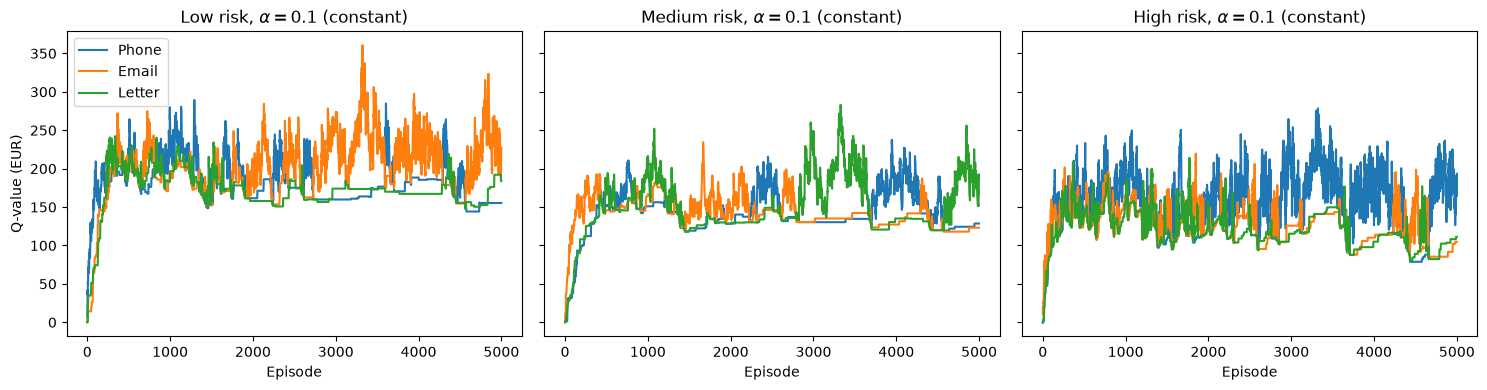

Policy: {'Low risk': 'Email', 'Medium risk': 'Letter', 'High risk': 'Phone'}


,Phone,Email,Letter
Low risk,155.3,227.1,183.7
Medium risk,128.6,123.1,187.4
High risk,193.3,104.9,111.3


In [19]:
##########################################################
## Many episodes, constant learning rate                 ##
##########################################################
def plot_q_history(history, axes, title):
    """Plots the Q-values over the episodes, one small plot per state.

    Args:
        history (list): The Q-table after every episode, as returned by q_learning.
        axes (array): Three matplotlib axes, one for each state.
        title (str): A label for the row of plots, shown above the plots, e.g. the learning rate.

    Returns:
        None
    """
    h = np.array(history)                            # shape: episodes x states x actions
    for i in range(len(states)):                     # one plot per state
        for j in range(len(actions)):                # one line per action
            axes[i].plot(h[:, i, j], label=actions[j])
        axes[i].set_title(states[i] + ', ' + title)  # the state and the learning rate in every title
        axes[i].set_xlabel('Episode')
    axes[0].set_ylabel('Q-value (EUR)')
    axes[0].legend()

def get_policy(q):
    """Returns the best action in each state.

    Args:
        q (np.ndarray): The Q-table, one row per state and one column per action.

    Returns:
        dict: State -> the action with the largest Q-value in that state.
    """
    policy = {}                                      # an empty dictionary, one entry per state
    for i in range(len(states)):                     # loop over the states
        policy[states[i]] = actions[int(np.argmax(q[i]))]
    return policy



alpha0 = 0.1                                         # the starting learning rate, defined once and used below and in 5.2
random.seed(42)                                      # makes the run repeatable
q_const, history_const = q_learning(episodes=5000, alpha=alpha0)   # constant learning rate, no stopping rule

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
plot_q_history(history_const, axes, rf'$\alpha = {alpha0}$ (constant)')   # the label uses the same variable
plt.tight_layout()
plt.show()

print('Policy:', get_policy(q_const))
pd.DataFrame(q_const, index=states, columns=actions).round(1)   # the final Q-table

### 5.2 A decaying learning rate

With a constant learning rate, every contact moves the Q-value by the same fraction $\alpha$ of the error. The rewards are random, so the Q-values keep **hovering** around the true value and never settle. A learning rate that **shrinks** over the episodes damps this:

$$\alpha_t = \frac{\alpha_0}{1 + t / 1000}$$

where $t$ is the episode number and $\alpha_0 = 0.1$. So $\alpha$ is 0.1 at the start, 0.05 at episode 1,000, and about 0.017 at episode 5,000.

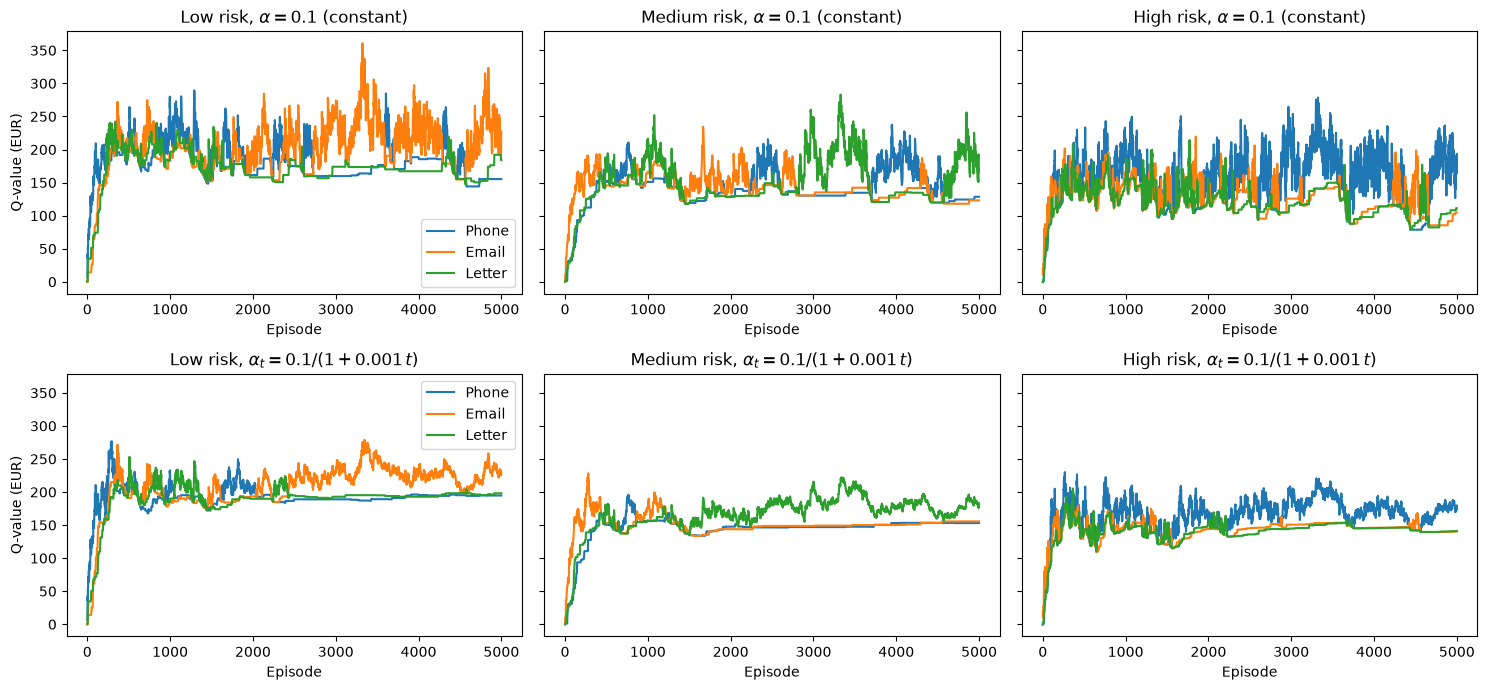

Policy, constant learning rate: {'Low risk': 'Email', 'Medium risk': 'Letter', 'High risk': 'Phone'}
Policy, decaying learning rate: {'Low risk': 'Email', 'Medium risk': 'Letter', 'High risk': 'Phone'}


In [20]:
##########################################################
## Constant against decaying learning rate               ##
##########################################################
decay = 0.001                                         # alpha_t = alpha0 / (1 + decay * t), alpha0 is defined in 5.1

random.seed(42)                                       # the same seed as in 5.1, so the two runs are comparable
q_decay, history_decay = q_learning(episodes=5000, alpha=alpha0, alpha_decay=decay)

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
plot_q_history(history_const, axes[0], rf'$\alpha = {alpha0}$ (constant)')
plot_q_history(history_decay, axes[1], rf'$\alpha_t = {alpha0} / (1 + {decay}\,t)$')
plt.tight_layout()
plt.show()

print('Policy, constant learning rate:', get_policy(q_const))
print('Policy, decaying learning rate:', get_policy(q_decay))

### 5.3 A stopping rule

How do we decide that the Q-values have converged? We stop early when **every** Q-value has stayed within a small band over the last `window` episodes:

$$\max_{u \in \text{window}} Q_u(s, a) - \min_{u \in \text{window}} Q_u(s, a) < \text{tolerance}, \quad \text{for all } (s, a)$$

- The window is the last 100 episodes
- The tolerance is in EUR. It cannot be 0, because with a constant learning rate the values never stop moving. We start with 20 EUR
- The rule is not checked before 500 episodes
- The run stops at the first of two things: the rule is met, or 5,000 episodes are done

In [22]:
##########################################################
## The stopping rule, with both learning rates           ##
##########################################################
tolerance = 20.0                                   # the band in EUR; try other values

# The two settings to compare: a name and the alpha_decay to use (alpha0 is defined in 5.1, decay in 5.2)
settings = [('Constant learning rate', 0.0),
            ('Decaying learning rate', decay)]

for name, alpha_decay in settings:                 # loop over the two settings
    random.seed(42)                                # the same seed as in 5.1 and 5.2
    q_s, history_s = q_learning(episodes=5000, alpha=alpha0,
                                alpha_decay=alpha_decay, tolerance=tolerance)
    print(f'{name}: ran {len(history_s)} of 5000 episodes')
    print(f'  Policy: {get_policy(q_s)}')

Constant learning rate: ran 5000 of 5000 episodes
  Policy: {'Low risk': 'Email', 'Medium risk': 'Letter', 'High risk': 'Phone'}
Decaying learning rate: ran 4174 of 5000 episodes
  Policy: {'Low risk': 'Email', 'Medium risk': 'Letter', 'High risk': 'Phone'}


**QUESTIONS:**

- Look at the plots with the constant learning rate. Do the Q-values converge? Which lines are still moving, and which are flat? Why are some flat?
- Compare the constant and the decaying learning rate. What happens to the wobble of the lines? Why does shrinking $\alpha$ have that effect, and what is the price?
- How would you decide, from a plot, that the Q-values have converged? Compare your answer with the stopping rule in 5.3
- Does the stopping rule fire with the constant learning rate? With the decaying one? Try tolerances of 5 and 50. What do you see?
- Can the stopping rule fire while a Q-value is still wrong? Think about a state-action pair that the agent almost never tries
- Compare the learned policy with your answer to the expected-reward question in Section 3. Do they agree? If not, which would you trust, and why?
- Rerun with another seed, for example 1 and 7. Does the policy change? In which state, and why?
- Change $\gamma$ to 0.5 and to 0.99. How do the Q-values and the policy change? What does $\gamma$ mean for the contact strategy?
- Change $\alpha_0$ to 0.5 and to 0.01. What happens to the convergence plot?

## 6. The Policy

### 6.1 Reading the policy off the Q-table

A **policy** is a rule that gives an action for each state. Once the Q-values are learned, the best policy takes, in every state, the action with the largest Q-value:

$$\pi^*(s) = \arg\max_a Q(s, a)$$

We use the Q-table from the run with the decaying learning rate in 5.2 (`q_decay`), because its values are the steadiest. The function `get_policy` from 5.1 applies the formula to every row of the table.

In [ ]:
##########################################################
## The policy: the best action in each state            ##
##########################################################
policy = get_policy(q_decay)       # the best action in each state, from the Q-table of 5.2 (decaying learning rate)

print('Policy derived from the Q-table:')
for state in states:               # loop over the states, from low to high risk
    print(f'  In state {state}, the best action is: {policy[state]}')

pd.DataFrame(q_decay, index=states, columns=actions).round(1)   # the Q-table the policy comes from

Policy derived from the Q-table:
  In state Low risk, the best action is: Email
  In state Medium risk, the best action is: Letter
  In state High risk, the best action is: Phone


,Phone,Email,Letter
Low risk,194.7,229.2,198.1
Medium risk,153.0,155.6,182.6
High risk,179.5,140.5,140.9


**QUESTIONS:**

- In `get_policy`, find where the policy is calculated for every state. How does it correspond to the definition $\pi^*(s) = \arg\max_a Q(s, a)$ from the lecture?
- Do you agree with the policy calculated from the Q-table? What do the Q-values represent, and in which unit?
- Look at the Q-table. How large is the gap between the best action and the other two in each state? How confident are you in the ranking?
- Would you use this policy in practice? What would you check first? Think about where the payment probabilities come from, the three features that define the states, and how the channel was chosen in the past.
- What does the policy leave out? Think about a debtor's history, legal limits on how often a debtor may be contacted, and the timing of a contact.
- A phone call costs 4.20 EUR. Double the cost in Section 2 and rerun Sections 2 to 5. Does the policy change? In which state, and why?
- How does a policy differ from the prediction models of the earlier notebooks? What does it tell the agency that a predicted probability does not?

## 7. Beyond the Q-table: Deep Q-Networks (future steps)

The Q-table works here because the problem is tiny: 3 states and 3 actions give 9 values. It breaks down when the debtor state becomes a rich, continuous feature vector. In the full problem, a **neural network replaces the Q-table** as a function approximator. This is the **Deep Q-Network (DQN)**, and the step from Q-learning to DQN is what made reinforcement learning work on large problems.

We do not build it here. The table shows what changes:

| Component | Stage 1: Q-table (this notebook) | Stage 2: Deep Q-Network |
|---|---|---|
| State | 3 risk categories, from the predicted probability of repayment | A continuous vector: debtor attributes, supervised model outputs, NLP scores, SVD embeddings and NMF topic weights |
| Action | 3 channels: phone, email, letter | Channel × timing × message type: phone, email, SMS or letter, a delay in days, and a reminder, plan or settlement message |
| Reward | Repayment received minus contact cost | Repayment received minus contact cost minus a complaint penalty |
| Q-function | A table with one value per state-action pair | A neural network that approximates $Q(s, a)$ over the continuous state space |
| Policy | ε-greedy, from the Q-table | ε-greedy, from the Q-network |

### How a neural network can replace the Q-table

- **A table is a lookup.** Give it a state, and it returns that row of Q-values. It has one row per state, so it only works when the states can be listed
- **A network is a function.** Give it the state's features, and it **computes** one Q-value per action, for any state, including states it has never seen
- **It learns from the same Bellman target as before.** The Q-table moves one cell toward the target. The network takes a gradient step that moves its prediction $Q(s, a)$ toward the target, with the squared error as the loss:

$$L = \Big( r + \gamma \max_{a'} Q(s', a') - Q(s, a) \Big)^2$$

- **So training a DQN is a regression**, in which the labels come from the Bellman equation
- **Similar states get similar Q-values.** A table learns every row separately. A network shares its weights, so what it learns in one place carries over to others


**QUESTIONS:**

- Suppose the state had 10 continuous features, and we cut each into 10 levels. How many rows would the Q-table have? How many Q-values with our 3 actions? Could the agent visit every row in 5,000 episodes?
- Our states use only three features of an account. What do we throw away? Which information from the earlier notebooks could enter a richer state?
- A Q-table stores one value per state-action pair and says nothing about a state it has never visited. What does a function approximator do differently? What do you give up in return?
- Which earlier notebook does a neural network that maps a state to Q-values remind you of? What would its inputs and outputs be?
- Moving from 3 actions to channel × timing × message type changes the problem. What new difficulties do you expect?

**Future steps**

- Build the state vector for each debtor from the outputs of the earlier notebooks, including the SVD embeddings saved in `svd_embeddings.pkl`
- Define the larger action space, and add the complaint penalty to the reward
- Train a DQN, and compare the policy it learns with the one from the Q-table